# Draft A: training the pooled CNN-7 (admissible pooling)

Trains CNN-7 with its stride-2 convolution replaced by 2x2 interval max-pooling, with IBP and the
sound pooling operators `lattice` and `lex2`, plus a normally trained control (`std`), on the standard
certified-training benchmarks: MNIST (eps 0.1, 0.3) and CIFAR-10 (eps 2/255, 8/255). The recipe follows
Shi et al. (2021) and CTBench: robust loss on margin bounds, smoothed eps schedule, warm-up regularizers.
`('ref', 'cnn7')` is the unmodified CNN-7, which checks the recipe against the published numbers.
Lex1 and Xu-Yager are unsound and are only swapped in at evaluation (last section).

In [7]:
import os, sys, glob, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path[:0] = [ROOT, os.path.join(ROOT, 'scripts')]
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# IGNN_RUNS / IGNN_OUT only redirect outputs for testing; leave them unset for real runs.
RUNS = os.environ.get('IGNN_RUNS', os.path.join(ROOT, 'runs'))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('root:', ROOT, '| runs:', RUNS, '| device:', DEVICE)

root: e:\university\Projects\Bachlour | runs: e:\university\Projects\Bachlour\runs | device: cuda


In [8]:
from interval_gnn.experiments import load_config, deep_update, run_experiment

BENCHMARKS = [('mnist', 'eps01'), ('mnist', 'eps03'), ('cifar10', 'eps8'), ('cifar10', 'eps2')]
MODELS = [('ref', 'cnn7'), ('std', 'pool1'), ('lattice', 'pool1'), ('lex2', 'pool1')]
# the two-pooling-layer variant has its own section below
SEEDS = [0, 1, 2]
OVERRIDES = {}                           # quick check: {'train': {'epochs': 2}, 'data': {'subset': 1024}}

In [9]:
tests = []
for ds, tag in BENCHMARKS:
    for op, layout in MODELS:
        cfg = deep_update(load_config(os.path.join(ROOT, 'configs', 'A', f'{ds}_{op}_{layout}_{tag}.json')), OVERRIDES)
        for seed in SEEDS:
            res = run_experiment(cfg, seed, root=RUNS, device=DEVICE)
            tests.append(res['test'])
tests = pd.concat(tests, ignore_index=True)
display(tests.pivot_table(index=['dataset', 'model'], columns='eps', values='verified_acc', aggfunc='mean').round(4))

skip (done): e:\university\Projects\Bachlour\runs\A\mnist\ref_cnn7_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\ref_cnn7_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\ref_cnn7_eps01\seed2
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\std_pool1_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\std_pool1_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\std_pool1_eps01\seed2
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool1_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool1_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool1_eps01\seed2
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool1_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool1_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool1_eps01\seed2
skip (done): e:\university\P

eps                          0.000000  0.007843  0.031373  0.100000  0.300000
dataset model                                                                
cifar10 lattice_pool1_eps2     0.6744    0.5308       NaN       NaN       NaN
        lattice_pool1_eps8     0.4813       NaN    0.3411       NaN       NaN
        lex2_pool1_eps2        0.6734    0.5259       NaN       NaN       NaN
        lex2_pool1_eps8        0.4714       NaN    0.3325       NaN       NaN
        ref_cnn7_eps2          0.6705    0.5283       NaN       NaN       NaN
        ref_cnn7_eps8          0.4787       NaN    0.3392       NaN       NaN
        std_pool1_eps2         0.9086    0.0000       NaN       NaN       NaN
        std_pool1_eps8         0.9098       NaN    0.0000       NaN       NaN
mnist   lattice_pool1_eps01    0.9906       NaN       NaN    0.9645       NaN
        lattice_pool1_eps03    0.9843       NaN       NaN       NaN    0.9303
        lex2_pool1_eps01       0.9910       NaN       NaN    0.9646       NaN
        lex2_pool1_eps03       0.9824       NaN       NaN       NaN    0.9257
        ref_cnn7_eps01         0.9916       NaN       NaN    0.9651       NaN
        ref_cnn7_eps03         0.9849       NaN       NaN       NaN    0.9322
        std_pool1_eps01        0.9956       NaN       NaN    0.0000       NaN
        std_pool1_eps03        0.9958       NaN       NaN       NaN    0.0000

## Two pooling layers (`pool2`)

CNN-7 with a second 2x2 pooling layer after the second convolution, trained with the lattice maximum
and with Lex2. It tests Thm `thm:compare` with more than one pooling layer. Runs go to
`runs/A/<dataset>/<op>_pool2_<eps tag>/seed<k>/` like the others, and the swap evaluation at the end of
this notebook picks them up. The feature maps are smaller after the early pooling, so an epoch takes
roughly half as long as `pool1`. Seed 0 of every config runs first, so a stopped run still leaves one
result per config; finished runs are skipped and interrupted ones resume.

In [10]:
POOL2_BENCHMARKS = [('mnist', 'eps01'), ('mnist', 'eps03'), ('cifar10', 'eps8'), ('cifar10', 'eps2')]
POOL2_MODELS = [('lattice', 'pool2'), ('lex2', 'pool2')]
POOL2_SEEDS = [0, 1, 2]

tests2 = []
for seed in POOL2_SEEDS:
    for ds, tag in POOL2_BENCHMARKS:
        for op, layout in POOL2_MODELS:
            cfg = deep_update(load_config(os.path.join(ROOT, 'configs', 'A', f'{ds}_{op}_{layout}_{tag}.json')), OVERRIDES)
            res = run_experiment(cfg, seed, root=RUNS, device=DEVICE)
            tests2.append(res['test'])
tests2 = pd.concat(tests2, ignore_index=True)
display(tests2.pivot_table(index=['dataset', 'model'], columns='eps', values='verified_acc', aggfunc='mean').round(4))

skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool2_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool2_eps01\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool2_eps03\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool2_eps03\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\cifar10\lattice_pool2_eps8\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\cifar10\lex2_pool2_eps8\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\cifar10\lattice_pool2_eps2\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\cifar10\lex2_pool2_eps2\seed0
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool2_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool2_eps01\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lattice_pool2_eps03\seed1
skip (done): e:\university\Projects\Bachlour\runs\A\mnist\lex2_pool2_eps03\seed1
skip (

eps                          0.000000  0.007843  0.031373  0.100000  0.300000
dataset model                                                                
cifar10 lattice_pool2_eps2     0.6669    0.5276       NaN       NaN       NaN
        lattice_pool2_eps8     0.4701       NaN    0.3333       NaN       NaN
        lex2_pool2_eps2        0.6558    0.5210       NaN       NaN       NaN
        lex2_pool2_eps8        0.4403       NaN    0.3099       NaN       NaN
mnist   lattice_pool2_eps01    0.9885       NaN       NaN    0.9674       NaN
        lattice_pool2_eps03    0.9772       NaN       NaN       NaN    0.9166
        lex2_pool2_eps01       0.9894       NaN       NaN    0.9662       NaN
        lex2_pool2_eps03       0.9698       NaN       NaN       NaN    0.8934

## Training curves

Validation clean and verified accuracy, training loss and gradient norm per epoch (H5: training with
Lex2 is expected to be less stable than with the lattice maximum).

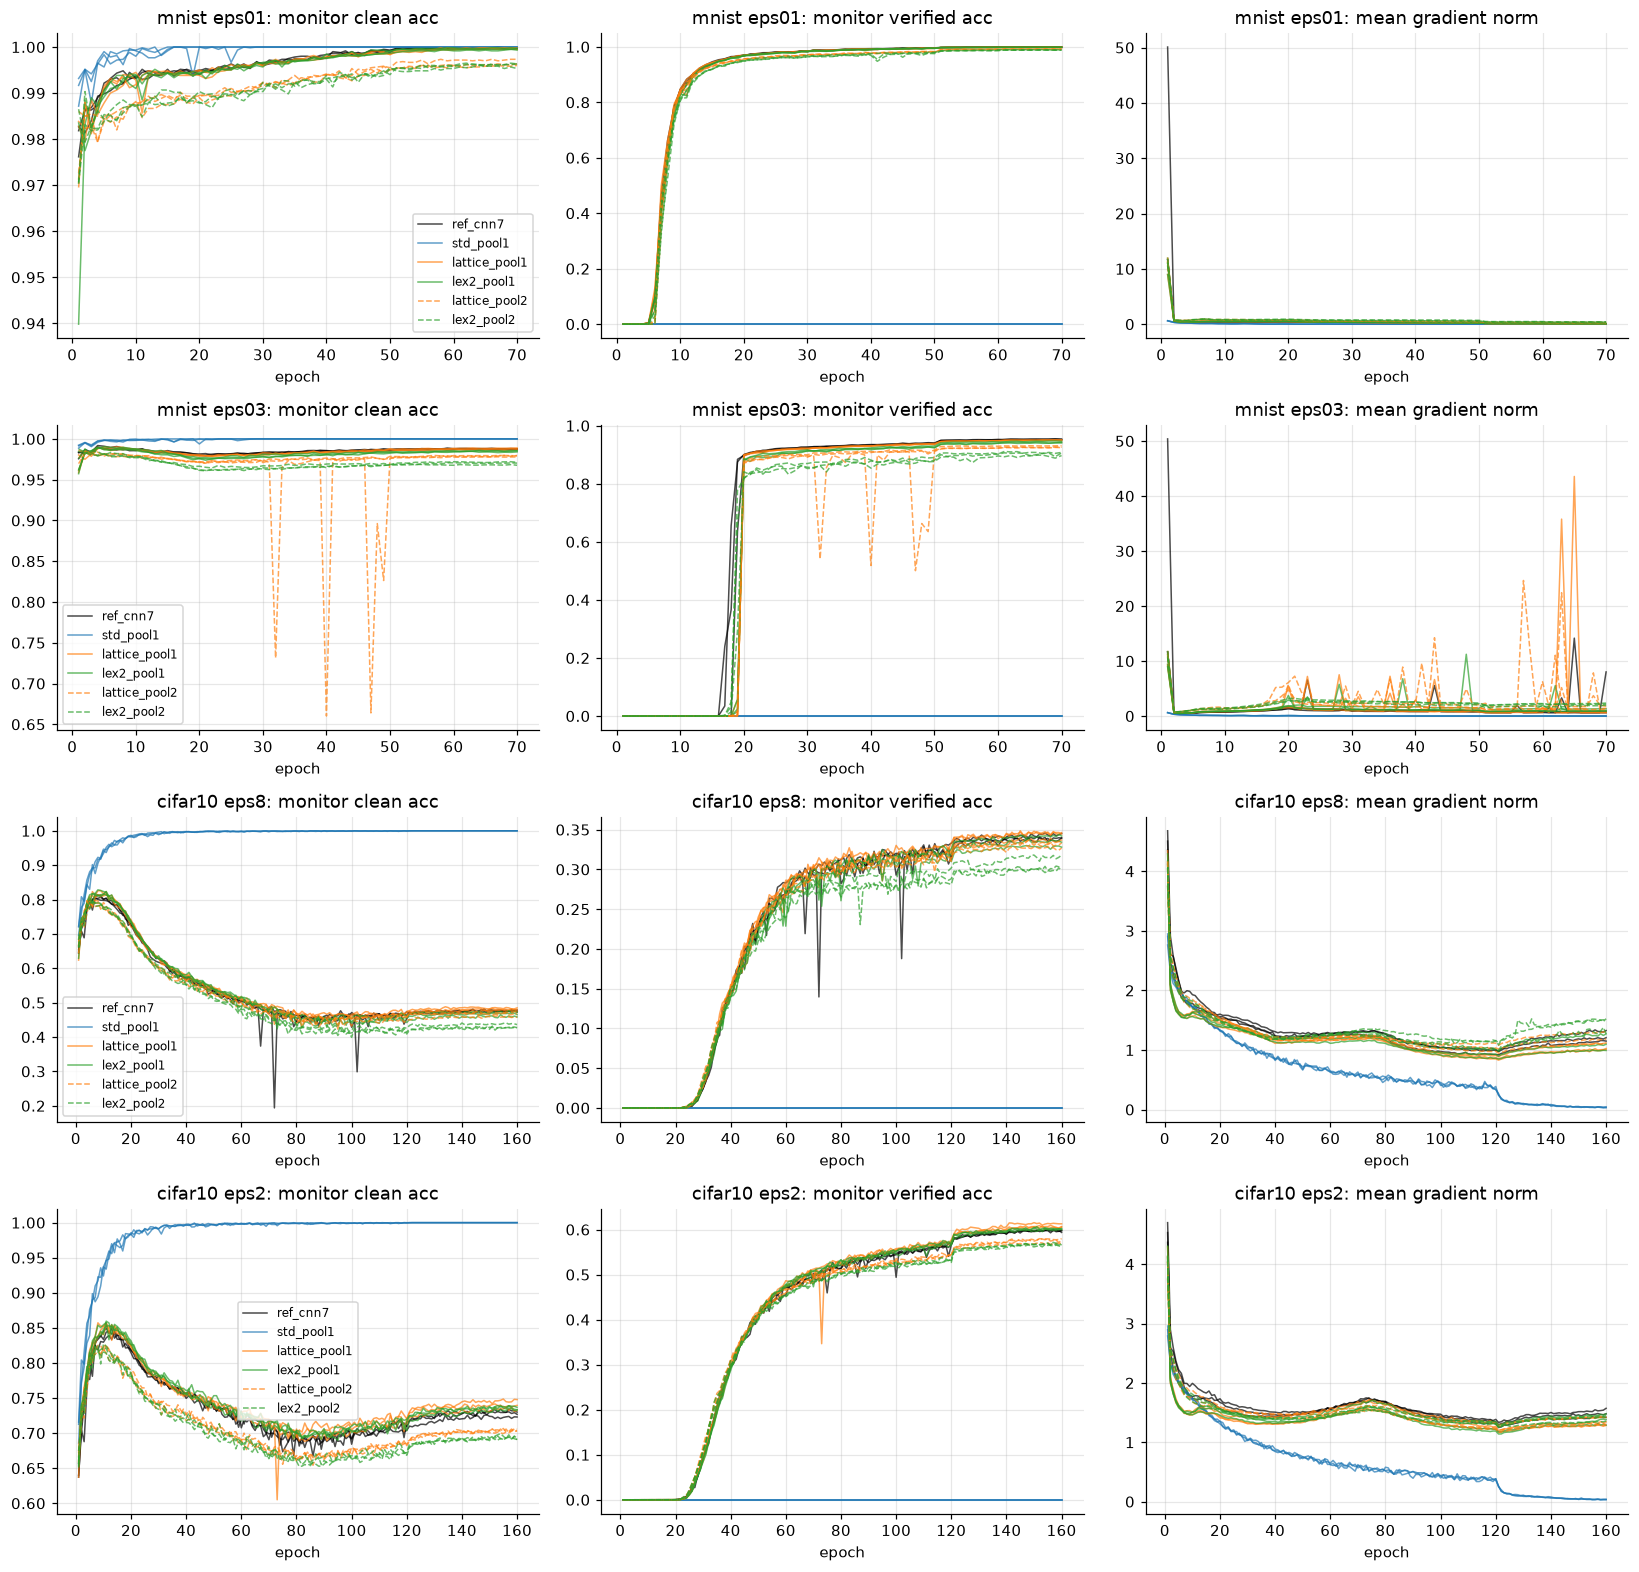

In [11]:
fig, axes = plt.subplots(len(BENCHMARKS), 3, figsize=(15, 3.6 * len(BENCHMARKS)), squeeze=False)
for row, (ds, tag) in zip(axes, BENCHMARKS):
    for op, layout in MODELS + [('lattice', 'pool2'), ('lex2', 'pool2')]:
        for f in sorted(glob.glob(os.path.join(RUNS, 'A', ds, f'{op}_{layout}_{tag}', 'seed*', 'metrics.csv'))):
            m = pd.read_csv(f)
            lab = f'{op}_{layout}' if f.endswith(os.path.join('seed0', 'metrics.csv')) else None
            kw = dict(color={'ref': 'k', 'std': 'C0', 'lattice': 'C1', 'lex2': 'C2'}[op], alpha=0.7, lw=1, label=lab, ls='--' if layout == 'pool2' else '-')
            row[0].plot(m.epoch, m.val_acc, **kw)
            row[1].plot(m.epoch, m.val_verified, **kw)
            row[2].plot(m.epoch, m.grad_norm, **kw)
    for ax, t in zip(row, ['monitor clean acc', 'monitor verified acc', 'mean gradient norm']):
        ax.set(title=f'{ds} {tag}: {t}', xlabel='epoch'); ax.grid(alpha=.3)
    row[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Swap evaluation (H1-H4)

Each trained network is evaluated with all four pooling operators on the same weights: violation
rate by sampling the input box, clean and verified accuracy, and the width of the predicted logit
relative to the lattice operator. Results go to `swap_results.csv` in each run directory.

In [12]:
from A_swap_eval import swap_eval
from interval_gnn.experiments import load_run

N_INPUTS, N_SAMPLES, N_CORNERS = 500, 100, 20
for path in sorted(os.path.dirname(f) for f in glob.glob(os.path.join(RUNS, 'A', '*', '*', 'seed*', 'done.flag'))):
    out = os.path.join(path, 'swap_results.csv')
    if os.path.exists(out):
        continue
    cfg, task, model = load_run(path, DEVICE)
    if not model.pools:
        continue                                # the cnn7 reference has no pooling layer
    df = swap_eval(model, task, cfg['train']['eps'], N_INPUTS, N_SAMPLES, N_CORNERS, margin=cfg['train'].get('margin', False))
    df.insert(0, 'trained_with', cfg['model']['pool'] if cfg['train']['ibp'] else 'std')
    df.to_csv(out, index=False)
    print(path); display(df.round(4))